# Environment Setup
We will create a virtual environment and install the required packages to ensure all dependencies for HSI segmentation are met.

# Segmentation

In [ ]:
!nvidia-smi

Wed Apr  8 12:37:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.94                 Driver Version: 560.94         CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060      WDDM  |   00000000:01:00.0  On |                  N/A |
|  0%   42C    P8             21W /  170W |     761MiB /  12288MiB |     13%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: C:\Users\34118171\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import cv2
import keras
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time
from keras import backend as K
from keras import layers
from datasets import load_dataset
from PIL import Image

print('Libraries imported successfully from:', lib_path)
print('TensorFlow version:', tf.__version__)
print('Keras version:', keras.__version__)

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
from tensorflow.keras import mixed_precision
# mixed_precision.set_global_policy("float16")
mixed_precision.set_global_policy("float32")

https://huggingface.co/datasets/LujianYao/HSSDataset

In [ ]:
# Mount the google drive
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
## This part is when formatting the data

# # Define the path in Google Drive where you want to clone the dataset
# colab_path = "/content/HSSDataset"
# destination_path = '/content/drive/MyDrive/Colab Notebooks/Module-CV/HSSDataset'

# # Create the directory if it doesn't exist
# if not os.path.exists(colab_path) and not os.path.exists(destination_path):
#     os.makedirs(colab_path, exist_ok=True)
#     os.makedirs(destination_path, exist_ok=True)
#     print(f"Directory '{colab_path}' created.")
#     print(f"Directory '{destination_path}' created.")

#     # Change the current working directory to the drive path
#     %cd {colab_path}

#     # Clone the dataset using git lfs
#     !git lfs install
#     # Ensure git lfs is installed
#     !git clone https://huggingface.co/datasets/LujianYao/HSSDataset .

#     print(f"Dataset cloned into '{colab_path}'")
# else:
#     print(f"Dataset already exists. Skipping creation.")

In [ ]:
time.sleep(1)

In [ ]:
# !git lfs install
# !git clone https://huggingface.co/datasets/LujianYao/HSSDataset

In [ ]:
# ## This part is when formatting the data

# arr = np.load(os.path.join(colab_path, "HSS_VOC/npy_multichannel/10_frame_0001.npy"))
# arr.shape

In [ ]:
# ## This part is when formatting the data

# arr = np.load(os.path.join(colab_path, "HSS_VOC/npy_multichannel/11_frame_0433.npy"))
# arr.shape

In [ ]:
# ## This part is when formatting the data
# len(os.listdir("/content/HSSDataset/HSS_VOC/npy_multichannel"))

In [ ]:
time.sleep(1)

In [ ]:
# ## This part is when formatting the data

# dataset_root = "/content/HSSDataset/HSS_VOC"
# hsi_data_dir = "npy_multichannel"
# splits = ['split/train.txt', 'split/val.txt', 'split/test.txt']
# total_files = 0

# for split in splits:
#     with open(os.path.join(dataset_root, split), 'r') as f:
#         # count number of files in each set
#         files = f.readlines()
#         print(f"Files in {split.rsplit('/', 1)[-1]}", n_files:=len(files))
#         total_files += n_files

#         # check existance of all files
#         for file in files:
#             file_path = os.path.join(dataset_root, hsi_data_dir, file.strip() + '.npy')
#             if not os.path.exists(file_path):
#                 print(f"Warning: File {file_path} does not exist")

#             # check dimension mismatch
#             # shape = None
#             # arr = np.load(file_path)

#             # if shape is None:
#             #     shape = arr.shape
#             # else:
#             #     if shape != arr.shape:
#             #         print(f"Warning: File {file_path} has different shape")

# print(f"Total number of files: {total_files}")

In [ ]:
# # Formatting the data inside particular directories based on train.txt, val.txt
# # and test.txt files

# import os
# import shutil


# data_root = "/content/HSSDataset"
# hsi_data_dir = "npy_multichannel"
# mask_data_dir = "Mask"
# split_dir = "split"
# destination_root = "/content/drive/MyDrive/Colab Notebooks/Module-CV/HSSDataset"

# splits = {
#     "train": "train.txt",
#     "val": "val.txt",
#     "test": "test.txt"
# }

# print("Starting dataset organization...")

# for split_name, split_file in splits.items():
#     split_filepath = os.path.join(dataset_root, split_dir, split_file)

#     dest_image_dir = os.path.join(destination_root, split_name, "images")
#     dest_mask_dir = os.path.join(destination_root, split_name, "masks")

#     os.makedirs(dest_image_dir, exist_ok=True)
#     os.makedirs(dest_mask_dir, exist_ok=True)

#     print(f"Processing {split_name} split using {split_filepath}")

#     with open(split_filepath, 'r') as f:
#         filenames = f.readlines()

#         for file_base in filenames:
#             file_base = file_base.strip() # Remove newline characters

#             # Source paths
#             src_image_path = os.path.join(dataset_root, hsi_data_dir, file_base + '.npy')
#             src_mask_path = os.path.join(dataset_root, mask_data_dir, file_base + '.png')

#             # Destination paths
#             dest_image_path = os.path.join(dest_image_dir, file_base + '.npy')
#             dest_mask_path = os.path.join(dest_mask_dir, file_base + '.png')

#             if os.path.exists(src_image_path) and os.path.exists(src_mask_path):
#                 shutil.copy(src_image_path, dest_image_path)
#                 time.sleep(0.01)
#                 shutil.copy(src_mask_path, dest_mask_path)
#                 time.sleep(0.01)
#             else:
#                 print(f"Warning: Skipping {file_base} - Image or mask not found: {src_image_path}, {src_mask_path}")

# print("Dataset organization complete!")

In [ ]:
## This section is copying data from drive to colab for faster access of data

import os
import shutil

source_base_dir = "/content/drive/MyDrive/Colab Notebooks/Module-CV/HSSDataset"
dest_base_dir = "/content/HSSDataset_Splitted"

splits = ["train", "val", "test"]

print(f"Starting data replication from {source_base_dir} to {dest_base_dir}...")

for split_name in splits:
    source_image_dir = os.path.join(source_base_dir, split_name, "images")
    source_mask_dir = os.path.join(source_base_dir, split_name, "masks")

    dest_image_dir = os.path.join(dest_base_dir, split_name, "images")
    dest_mask_dir = os.path.join(dest_base_dir, split_name, "masks")

    os.makedirs(dest_image_dir, exist_ok=True)
    os.makedirs(dest_mask_dir, exist_ok=True)

    print(f"Processing {split_name} split...")

    # Copy images
    if os.path.exists(source_image_dir):
        image_files = os.listdir(source_image_dir)
        for img_file in image_files:
            shutil.copy(os.path.join(source_image_dir, img_file), dest_image_dir)
            time.sleep(0.01)
    else:
        print(f"Warning: Source image directory not found for {split_name}: {source_image_dir}")

    # Copy masks
    if os.path.exists(source_mask_dir):
        mask_files = os.listdir(source_mask_dir)
        for mask_file in mask_files:
            shutil.copy(os.path.join(source_mask_dir, mask_file), dest_mask_dir)
            time.sleep(0.01)
    else:
        print(f"Warning: Source mask directory not found for {split_name}: {source_mask_dir}")

print("Data replication complete!")


Starting data replication from /content/drive/MyDrive/Colab Notebooks/Module-CV/HSSDataset to /content/HSSDataset_Splitted...
Processing train split...
Processing val split...
Processing test split...
Data replication complete!


In [ ]:
time.sleep(1)

In [ ]:
splits = [split for split in os.listdir("/content/HSSDataset_Splitted") if os.path.isdir(os.path.join("/content/HSSDataset_Splitted", split))]
splits

['val', 'train', 'test']

In [ ]:
for split in splits:
    image_dir = os.path.join("/content/HSSDataset_Splitted", split, "images")
    mask_dir = os.path.join("/content/HSSDataset_Splitted", split, "masks")
    images, masks = os.listdir(image_dir), os.listdir(mask_dir)
    assert len(images) == len(masks), "Number of images and masks do not match"

    for image_file, mask_file in zip(sorted(images), sorted(masks)):
        assert image_file.rsplit('.')[0] == mask_file.rsplit('.')[0], "Image and mask filenames do not match"
        assert image_file.endswith('.npy'), "Image files should have .npy extension"


Displaying: 20_frame_0163


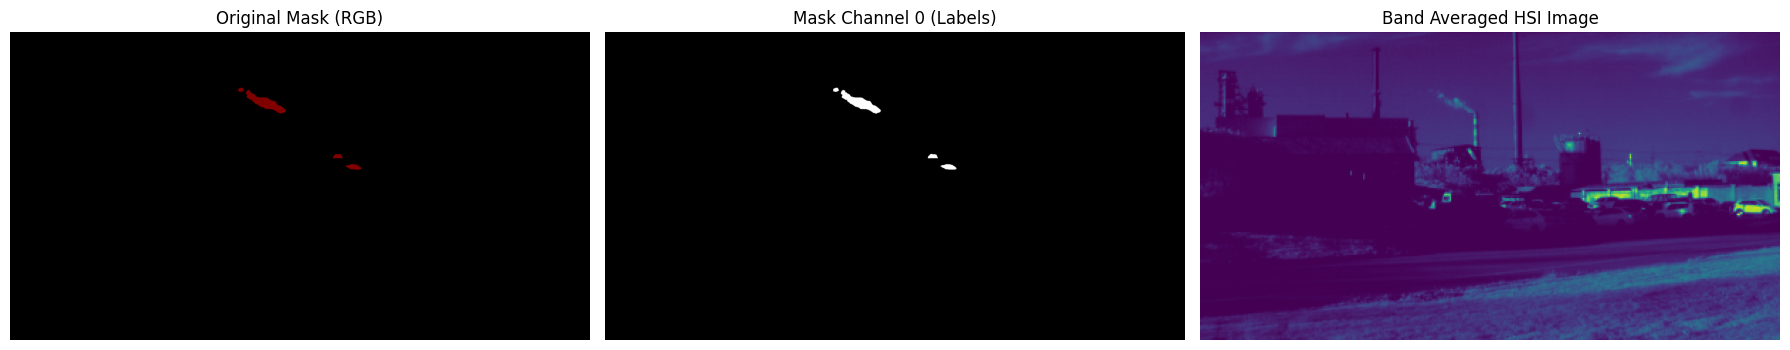

HSI Shape: (217, 409, 25)
Mask Shape: (1088, 2048, 3)


In [ ]:
import matplotlib.pyplot as plt
import os
import random
import numpy as np
import torch
from PIL import Image

# Path setup
train_dir = os.path.join(source_base_dir, "train/")
mask_dir = os.path.join(train_dir, "masks/")
image_dir = os.path.join(train_dir, "images/")

# Select a random pair
all_masks = [f for f in os.listdir(mask_dir) if f.endswith('.png')]
random_mask_name = random.choice(all_masks)
base_name = os.path.splitext(random_mask_name)[0]

mask_path = os.path.join(mask_dir, random_mask_name)
image_path = os.path.join(image_dir, base_name + ".npy")

print(f"Displaying: {base_name}")

# Load Mask using PIL (PyTorch-idiomatic way for image loading)
mask_pil = Image.open(mask_path)
mask_np = np.array(mask_pil) # Convert to numpy array for channel access and shape info
# mask_channel_0 = mask_np[:, :, 0] # Extract the first channel

# Load HSI Image (numpy loading remains the same)
hsi_image = np.load(image_path)
band_averaged = np.mean(hsi_image, axis=-1)

# Display
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Band Averaged HSI Image
axes[0].imshow(band_averaged, cmap="viridis")
axes[0].set_title("Band Averaged HSI Image")
axes[0].axis("off")

# Original
axes[1].imshow(mask_np)
axes[1].set_title("Original Mask")
axes[1].axis("off")

# Mask
axes[2].imshow(mask_np[:, :], cmap="gray")
axes[2].set_title("Mask with gray cmap")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print(f"HSI Shape: {hsi_image.shape}")
print(f"Mask Shape: {mask_np.shape}") # Changed to mask_np.shape for consistency

In [ ]:
import os
import numpy as np
from PIL import Image
from tqdm import tqdm

def count_non_background_pixels(dataset_root, split):
    """
    finds unique pixels in mask.

    Args:
        dataset_root (str): The root directory of the dataset.
        split (str): The dataset split (e.g., 'train', 'val', 'test').

    Returns:
        list: a set of unique pixel values found in channel 0.
    """
    mask_dir = os.path.join(dataset_root, split, "masks")
    if not os.path.exists(mask_dir):
        print(f"Error: Mask directory not found for split '{split}': {mask_dir}")
        return set()

    mask_files = [f for f in os.listdir(mask_dir) if f.endswith('.png')]

    unique_pixels = set()

    print(f"finding unique values in mask for {split} split...")
    for mask_file in tqdm(mask_files, desc=f"Processing {split} masks"):
        mask_path = os.path.join(mask_dir, mask_file)

        # Load mask and convert to numpy array
        mask_pil = Image.open(mask_path)
        mask_np = np.array(mask_pil)

        # unique pixels
        unique_pixels.update(np.unique(mask_np))

    # Convert unique pixel values to standard Python integers
    return sorted([int(x) for x in unique_pixels])


train_unique_pxl_values = count_non_background_pixels(source_base_dir, "train")
print(f"\nTrain Split - Channel 0 unique pixel values: {train_unique_pxl_values}")
print("---"*30)

val_unique_pxl_values = count_non_background_pixels(source_base_dir, "val")
print(f"\nValidation Split - Channel 0 unique pixel values: {val_unique_pxl_values}")
print("---"*30)

test_unique_pxl_values = count_non_background_pixels(source_base_dir, "test")
print(f"\nTest Split - Channel 0 unique pixel values: {test_unique_pxl_values}")
print("---"*30)

Why your HSI is 217×409×25 but the mask is 1088×2048

✅ 1. The HSI camera uses a 5×5 spectral mosaic filter
From the dataset page (XIMEA MQ022HG‑IM‑SM5X5‑NIR) :

The sensor has a 5×5 mosaic of spectral filters.

Each pixel on the sensor captures only one of the 25 spectral bands.

To reconstruct a full 25‑band cube, the raw mosaic is demosaiced, which reduces spatial resolution.

📉 2. Demosaicing reduces spatial resolution by a factor of 5
The raw sensor resolution is:

Code
1088 × 2048
But because each 5×5 block contains 25 different spectral filters, the reconstructed hyperspectral cube becomes:

Code
1088 / 5 = 217.6 → 217
2048 / 5 = 409.6 → 409
So the HSI shape:

Code
(217, 409, 25)
is exactly what you expect from a 5×5 mosaic demosaicing process.

🎯 3. The mask is drawn on the original full-resolution grayscale image
The dataset explains that annotators labeled masks on a band-averaged grayscale image generated from the raw mosaic frame (before demosaicing) .

That grayscale image has the original sensor resolution:

Code
1088 × 2048
So the mask PNGs match the raw sensor grid, not the demosaiced HSI grid.

In [ ]:
import tensorflow as tf
import os
import numpy as np

class HSSSegmentationDatasetTF:
    """
    A TensorFlow Dataset class for loading segmentation datasets from the HSSDataset structure.
    Modified for Conv1D: Reshapes (H, W, C) to (H*W, C).
    """
    def __init__(
        self,
        dataset_root="/content/HSSDataset_Splitted",
        image_dir="images",
        mask_dir="masks",
        image_size=(217, 409),
        batch_size=32,
        split="train",
        img_ext=".npy",
        mask_ext=".png",
        img_channels=25,
        mask_channels=3
    ):
        self.dataset_root = dataset_root
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size
        self.batch_size = batch_size
        self.image_paths = []
        self.mask_paths = []
        self.split = split
        self.img_ext = img_ext
        self.mask_ext = mask_ext
        self.img_channels = img_channels
        self.mask_channels = mask_channels
        self.mask_channels_desired = 1
        self._load_paths()

    def _load_paths(self):
        print(f"Inspecting dataset structure for segmentation at: {self.dataset_root}/{self.split}")
        current_split_images_path = os.path.join(self.dataset_root, self.split, self.image_dir)
        current_split_masks_path = os.path.join(self.dataset_root, self.split, self.mask_dir)

        if not os.path.isdir(current_split_images_path) or not os.path.isdir(current_split_masks_path):
            print(f"Error: Image or mask directory not found for split '{self.split}' at {self.dataset_root}")
            return

        image_filenames = sorted([f for f in os.listdir(current_split_images_path) if f.lower().endswith(self.img_ext)])

        for img_filename in image_filenames:
            base_filename = os.path.splitext(img_filename)[0]
            mask_filename = base_filename + self.mask_ext
            img_filepath = os.path.join(current_split_images_path, img_filename)
            mask_filepath = os.path.join(current_split_masks_path, mask_filename)

            if os.path.exists(img_filepath) and os.path.exists(mask_filepath):
                self.image_paths.append(img_filepath)
                self.mask_paths.append(mask_filepath)

        print(f"Found {len(self.image_paths)} image-mask pairs for split '{self.split}'.")

    def _load_npy(self, path):
        arr = np.load(path.decode("utf-8"))
        return arr.astype(np.float32)

    @tf.function
    def _parse_image_mask(self, image_path, mask_path):
        # 1. Load HSI (Numpy)
        image = tf.numpy_function(self._load_npy, [image_path], tf.float32)
        image.set_shape([self.image_size[0], self.image_size[1], self.img_channels])

        # 2. Load Mask and Resize to match HSI dimensions exactly
        mask_raw = tf.io.read_file(mask_path)
        mask = tf.image.decode_png(mask_raw, channels=1)
        # CRITICAL: Match the HSI size (217, 409)
        mask = tf.image.resize(mask, self.image_size, method='nearest')
        mask = tf.where(mask > 0, 1, 0)

        # 3. Reshape for Conv1D
        # Image: (H*W, Channels, 1) -> Conv1D expects (Steps, Feats)
        # We treat 25 channels as 25 "time steps"
        image = tf.reshape(image, [-1, self.img_channels, 1])

        # Mask: (H*W, 1)
        mask = tf.reshape(mask, [-1, self.mask_channels_desired])

        return image, mask

    def get_dataset(self, shuffle=False):
        path_ds = tf.data.Dataset.from_tensor_slices((self.image_paths, self.mask_paths))

        # Map the parsing logic
        dataset = path_ds.map(self._parse_image_mask, num_parallel_calls=tf.data.AUTOTUNE)

        # Flatten the spatial dimensions: This turns 1 image into 88,753 samples
        dataset = dataset.unbatch()

        # Cache here is powerful because it saves the reshaped/resized pixels
        # dataset = dataset.cache()

        if shuffle:
            # High buffer size needed because we are now shuffling individual pixels
            dataset = dataset.shuffle(buffer_size=150000)

        # Standard batching for Conv1D: results in (Batch, 25, 1)
        dataset = dataset.batch(self.batch_size)
        dataset = dataset.prefetch(tf.data.AUTOTUNE)

        return dataset

    # @tf.function
    # def _parse_image_mask(self, image_path, mask_path):
    #     image = tf.numpy_function(self._load_npy, [image_path], tf.float32)
    #     # Ensure the image has a known rank for resizing and subsequent operations
    #     # Allow height and width to be dynamic initially, but fix channels
    #     image.set_shape([None, None, self.img_channels])

    #     # Resize image to a consistent size
    #     # image = tf.image.resize(image, self.image_size)

    #     mask = tf.io.read_file(mask_path)
    #     mask = tf.image.decode_image(mask, channels=self.mask_channels, expand_animations=False)
    #     # the actual mask is the binary mask and is located in first channel
    #     # despite having 3 channels
    #     mask = mask[:, :, 0:1]
    #     # Resize mask to a consistent size using nearest neighbor for segmentation
    #     mask = tf.image.resize(mask, self.image_size, method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    #     mask = tf.cast(mask > 0, tf.uint8)

    #     # --- CHANGES FOR Conv1D ---
    #     # Reshape from (H, W, C) to (H*W, C, 1) for Conv1D input
    #     # Use -1 to infer the H*W dimension based on total elements and fixed (C, 1) dimensions
    #     image = tf.reshape(image, (-1, self.img_channels, 1))
    #     mask = tf.reshape(mask, (-1, self.mask_channels_desired))
    #     # --------------------------

    #     return image, mask

    # def get_dataset(self, shuffle=False):
    #     if not self.image_paths:
    #         return None

    #     path_ds = tf.data.Dataset.from_tensor_slices((self.image_paths, self.mask_paths))
    #     dataset = path_ds.interleave(
    #         lambda img, mask: tf.data.Dataset.from_tensors((img, mask)),
    #         cycle_length=8,
    #         num_parallel_calls=tf.data.AUTOTUNE
    #     )

    #     if shuffle:
    #         dataset = dataset.shuffle(buffer_size=len(self.image_paths))

    #     dataset = dataset.map(self._parse_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    #     dataset = dataset.cache()
    #     dataset = dataset.batch(self.batch_size)
    #     dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    #     return dataset

print("--- Loading HSSSegmentationDatasetTF (Conv1D Ready) ---")


--- Loading HSSSegmentationDatasetTF (Conv1D Ready) ---


In [ ]:

# train_segmentation_data = HSSSegmentationDatasetTF(
#     dataset_root="/content/HSSDataset_Splitted",
#     image_size=(217, 409),
#     batch_size=1024,
#     split="train",
#     img_channels=25
# )
# tf_train_dataset = train_segmentation_data.get_dataset(shuffle=True)

# val_segmentation_data = HSSSegmentationDatasetTF(
#     dataset_root="/content/HSSDataset_Splitted",
#     image_size=(217, 409),
#     batch_size=1024,
#     split="val",
#     img_channels=25
# )
# tf_val_dataset = val_segmentation_data.get_dataset(shuffle=False)

# test_segmentation_data = HSSSegmentationDatasetTF(
#     dataset_root="/content/HSSDataset_Splitted",
#     image_size=(217, 409),
#     batch_size=1024,
#     split="test",
#     img_channels=25
# )
# tf_test_dataset = test_segmentation_data.get_dataset(shuffle=False)

# if tf_train_dataset:
#     for image_batch, mask_batch in tf_train_dataset.take(1):
#         print(f"Shape of one image batch from train dataset: {image_batch.shape}") # (batch_size, image_height, image_width, channels)
#         print(f"Shape of one mask batch from train dataset: {mask_batch.shape}") # (batch_size, mask_height, mask_width, 1)
#         print(f"Example mask pixel values (first image in batch, top-left corner):\n {mask_batch[:10, 0].numpy()}")
#         break
# else:
#     print("Failed to create TensorFlow training dataset. Check warnings above.")


# if tf_val_dataset:
#     for image_batch, mask_batch in tf_val_dataset.take(1):
#         print(f"Shape of one image batch from validation dataset: {image_batch.shape}") # (batch_size, image_height, image_width, channels)
#         print(f"Shape of one mask batch from validation dataset: {mask_batch.shape}") # (batch_size, mask_height, mask_width, 1)
#         break
# else:
#     print("Failed to create TensorFlow validation dataset. Check warnings above.")

# if tf_test_dataset:
#     for image_batch, mask_batch in tf_test_dataset.take(1):
#         print(f"Shape of one image batch from test dataset: {image_batch.shape}") # (batch_size, image_height, image_width, channels)
#         print(f"Shape of one mask batch from test dataset: {mask_batch.shape}") # (batch_size, mask_height, mask_width, 1)
#         break
# else:
#     print("Failed to create TensorFlow test dataset. Check warnings above.")

# del tf_train_dataset
# del tf_val_dataset
# del tf_test_dataset


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models


def build_official_Justo_LiuNet(input_bands, num_classes):
    """
    The official 4,563 parameter version used on HYPSO-1.
    Note the kernel size increase to 6 and smaller filter widths.
    """
    inputs = layers.Input(shape=(input_bands, 1), name="Spectral_Input")

    # Block 1: 6 filters
    x = layers.Conv1D(6, 6, activation='relu', padding='same', name="Block1_Conv")(inputs)
    x = layers.MaxPooling1D(2, name="Block1_Pool")(x)

    # Block 2: 12 filters
    x = layers.Conv1D(12, 6, activation='relu', padding='same', name="Block2_Conv")(x)
    x = layers.MaxPooling1D(2, name="Block2_Pool")(x)

    # Block 3: 18 filters
    x = layers.Conv1D(18, 6, activation='relu', padding='same', name="Block3_Conv")(x)
    x = layers.MaxPooling1D(2, name="Block3_Pool")(x)

    # Block 4: 24 filters
    # x = layers.Conv1D(24, 6, activation='relu', padding='same', name="Block4_Conv")(x)
    # x = layers.MaxPooling1D(2, name="Block4_Pool")(x)

    # Classification Head (Direct to Output)
    x = layers.Flatten(name="Flatten")(x)
    # Removing the intermediate Dense(128) is the key to parameter reduction
    outputs = layers.Dense(num_classes, activation='sigmoid', dtype="float32", name="Predictions")(x)

    model = models.Model(inputs, outputs, name="Official_Justo_LiuNet")
    return model


def build_1D_Justo_LiuNet(input_bands, num_classes):
    """
    Keras implementation of the 1D-Justo-LiuNet.

    Args:
        input_bands (int): Number of spectral bands in the HSI data.
        num_classes (int): Number of target semantic classes.
    """
    # Input Layer: (Batch, Bands, 1)
    inputs = layers.Input(shape=(input_bands, 1), name="Spectral_Input")

    # Block 1: 32 Filters
    x = layers.Conv1D(filters=32, kernel_size=3, activation='relu', padding='same', name="Block1_Conv")(inputs)
    x = layers.MaxPooling1D(pool_size=2, name="Block1_Pool")(x)

    # Block 2: 32 Filters
    x = layers.Conv1D(filters=32, kernel_size=3, activation='relu', padding='same', name="Block2_Conv")(x)
    x = layers.MaxPooling1D(pool_size=2, name="Block2_Pool")(x)

    # Block 3: 64 Filters
    x = layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same', name="Block3_Conv")(x)
    x = layers.MaxPooling1D(pool_size=2, name="Block3_Pool")(x)

    # Block 4: 64 Filters
    # x = layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same', name="Block4_Conv")(x)
    # x = layers.MaxPooling1D(pool_size=2, name="Block4_Pool")(x)

    # Classification Head
    x = layers.Flatten(name="Flatten")(x)
    x = layers.Dense(128, activation='relu', name="Dense_128")(x)
    x = layers.Dropout(0.5, name="Dropout")(x) # Common practice for regularization
    outputs = layers.Dense(num_classes, activation='sigmoid', name="Predictions")(x)

    model = models.Model(inputs=inputs, outputs=outputs, dtype="float32", name="1D_Justo_LiuNet")

    return model

def build_1D_LiuNet_like(input_bands, num_classes):
    """
    Keras implementation of the 1D-Justo-LiuNet.

    Args:
        input_bands (int): Number of spectral bands in the HSI data.
        num_classes (int): Number of target semantic classes.
    """
    # Input Layer: (Batch, Bands, 1)
    inputs = layers.Input(shape=(input_bands, 1), name="Spectral_Input")

    # Block 1: 32 Filters
    x = layers.Conv1D(filters=16, kernel_size=3, activation='relu', padding='same', name="Block1_Conv")(inputs)
    x = layers.BatchNormalization(name="Block1_BN")(x)
    x = layers.Conv1D(filters=32, kernel_size=3, activation='relu', padding='same', name="Block1_Conv2")(x)
    x = layers.BatchNormalization(name="Block1_BN2")(x)
    x = layers.MaxPooling1D(pool_size=2, name="Block1_Pool")(x)

    # Block 2: 32 Filters
    x = layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same', name="Block2_Conv")(x)
    x = layers.BatchNormalization(name="Block2_BN")(x)
    x = layers.Conv1D(filters=128, kernel_size=3, activation='relu', padding='same', name="Block2_Conv2")(x)
    x = layers.BatchNormalization(name="Block2_BN2")(x)
    x = layers.MaxPooling1D(pool_size=2, name="Block2_Pool")(x)
    # x = layers.GlobalAveragePooling1D(name="Block2_Pool")(x)

    # Classification Head
    x = layers.Flatten(name="Flatten")(x)

    x = layers.Dense(512, activation='relu', name="Dense_1")(x)
    x = layers.Dropout(0.3, name="Dropout_1")(x) # Common practice for regularization

    x = layers.Dense(128, activation='relu', name="Dense_2")(x)
    x = layers.Dropout(0.3, name="Dropout_2")(x) # Common practice for regularization

    outputs = layers.Dense(num_classes, activation='sigmoid', name="Predictions")(x)

    model = models.Model(inputs=inputs, outputs=outputs, dtype="float32", name="1D_Justo_LiuNet")

    return model

# model = build_official_Justo_LiuNet(input_bands=25, num_classes=1)
# model = build_1D_Justo_LiuNet(input_bands=25, num_classes=1)
model = build_1D_LiuNet_like(input_bands=25, num_classes=1)
model.summary()

Model: "1D_Justo_LiuNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Spectral_Input (InputLayer)     │ (None, 25, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Conv (Conv1D)            │ (None, 25, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_BN (BatchNormalization)  │ (None, 25, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Conv2 (Conv1D)           │ (None, 25, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_BN2 (BatchNormalization) │ (None, 25, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Pool (MaxPooling1D)      │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Conv (Conv1D)            │ (None, 12, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_BN (BatchNormalization)  │ (None, 12, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Conv2 (Conv1D)           │ (None, 12, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_BN2 (BatchNormalization) │ (None, 12, 128)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Pool (MaxPooling1D)      │ (None, 6, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 512)            │       393,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Predictions (Dense)             │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 493,025 (1.88 MB)

 Trainable params: 492,545 (1.88 MB)

 Non-trainable params: 480 (1.88 KB)

In [ ]:
def balanced_accuracy(y_true, y_pred):
    """
    Calculates the mean of Sensitivity (True Positive Rate)
    and Specificity (True Negative Rate).
    """
    y_true = tf.cast(y_true, tf.float32)
    y_pred_pos = tf.cast(tf.greater(y_pred, 0.5), tf.float32)
    y_pred_neg = 1.0 - y_pred_pos

    y_true_pos = y_true
    y_true_neg = 1.0 - y_true

    # Sensitivity (Recall)
    tp = tf.reduce_sum(y_true_pos * y_pred_pos)
    fn = tf.reduce_sum(y_true_pos * y_pred_neg)
    sensitivity = tp / (tp + fn + K.epsilon())

    # Specificity
    tn = tf.reduce_sum(y_true_neg * y_pred_neg)
    fp = tf.reduce_sum(y_true_neg * y_pred_pos)
    specificity = tn / (tn + fp + K.epsilon())

    return (sensitivity + specificity) / 2.0

In [ ]:
import os
import tensorflow as tf
from tensorflow import keras
from keras import layers, models, callbacks
import numpy as np


class HSSDataLoader:
    def __init__(self, data_path, image_size, batch_size, split, img_channels, mask_channels):
        self.data_path = data_path
        # self.image_size = image_size
        self.batch_size = batch_size
        self.split = split
        self.img_channels = img_channels
        self.mask_channels = mask_channels

    def build_dataset(self, shuffle=True):
        dataset_loader = HSSSegmentationDatasetTF(
            dataset_root=self.data_path,
            image_dir="images",
            mask_dir="masks",
            # image_size=self.image_size,
            batch_size=self.batch_size,
            split=self.split,
            img_channels=self.img_channels,
            mask_channels=self.mask_channels
        )
        return dataset_loader.get_dataset(shuffle=shuffle)


class SegmentationTrainer:
    """
    Trainer class for UNet segmentation model.

    Handles model creation, compilation, training, and evaluation.
    """
    def __init__(self, train_path, val_path, test_path, input_shape, num_classes, base_filters, learning_rate, batch_size):
        """
        Initialize the trainer.

        Args:
            train_path: Path to training dataset (e.g., /content/HSSDataset_Splitted)
            val_path: Path to validation dataset
            test_path: Path to test dataset
            input_shape: Input image shape (height, width, channels)
            num_classes: Number of segmentation classes
            base_filters: Base number of filters in UNet
            learning_rate: Learning rate for optimizer
            batch_size: Batch size for training
        """
        self.train_path = train_path
        self.val_path = val_path
        self.test_path = test_path
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.base_filters = base_filters
        self.learning_rate = learning_rate
        self.batch_size = batch_size

        # Build model
        self.model = None
        self.history = None

    def build_model(self):
        """Build and compile the UNet model"""
        print("Building UNet model...")
        # self.model = build_official_Justo_LiuNet(input_bands=self.input_bands, num_classes=self.num_classes)
        # self.model = build_1D_Justo_LiuNet(input_bands=self.input_bands, num_classes=self.num_classes)
        self.model = build_1D_LiuNet_like(input_bands=self.input_bands, num_classes=self.num_classes)

        # Correct dummy input to match (Batch, Bands, 1)
        dummy_input = tf.ones((1,) + self.input_shape, dtype=tf.float32)
        _ = self.model(dummy_input, training=False)

        # Compile model with appropriate loss for binary segmentation
        # Using BinaryCrossentropy
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=self.learning_rate),
            loss=keras.losses.BinaryCrossentropy(from_logits=False),
            metrics=[
                'accuracy',
                balanced_accuracy,
                keras.metrics.BinaryIoU(target_class_ids=[1], threshold=0.5, name="mIOU"),
                tf.keras.metrics.F1Score(threshold=0.5, name="f1_score")
            ]
        )

        print("Model compiled successfully!")
        return self.model

    def prepare_datasets(self):
        """Create and prepare training and validation datasets"""
        print(f"Loading training data from: {self.train_path}")
        train_loader = HSSDataLoader(
            data_path=self.train_path,
            image_size=(217, 409),
            batch_size=self.batch_size,
            split="train",
            img_channels=25,
            mask_channels=1
        )
        train_dataset = train_loader.build_dataset(shuffle=True)

        print(f"Loading validation data from: {self.val_path}")
        val_loader = HSSDataLoader(
            data_path=self.val_path,
            image_size=(217, 409),
            batch_size=self.batch_size,
            split="val",
            img_channels=25,
            mask_channels=1
        )
        val_dataset = val_loader.build_dataset(shuffle=False)

        return train_dataset, val_dataset

    def train(self, epochs=50, save_path="../models"):
        """
        Train the model.

        Args:
            epochs: Number of training epochs
            save_path: Path to save model checkpoints

        Returns:
            Training history
        """
        # Create save directory
        os.makedirs(save_path, exist_ok=True)

        # Set internal variables needed for model building
        self.input_bands = self.input_shape[0]

        # Build and compile model
        self.build_model()

        assert self.model is not None, "Model building failed. Cannot train."

        # Print model summary
        self.model.summary()

        # Prepare datasets
        train_dataset, val_dataset = self.prepare_datasets()

        # Define callbacks
        callback_list = [
            # Save best model based on validation loss
            callbacks.ModelCheckpoint(
                filepath=os.path.join(save_path, "best_model.keras"),
                monitor='val_mIOU',
                save_best_only=True,
                mode='max',
                verbose=1
            ),
            # Early stopping
            callbacks.EarlyStopping(
                monitor='val_mIOU',
                patience=10,
                restore_best_weights=True,
                mode='max',
                verbose=1
            ),
            # Reduce learning rate on plateau
            callbacks.ReduceLROnPlateau(
                monitor='val_mIOU',
                factor=0.5,
                patience=5,
                min_lr=1e-7,
                mode='max',
                verbose=1
            ),
            # TensorBoard logging
            callbacks.TensorBoard(
                log_dir=os.path.join(save_path, "logs_1")
            )
        ]

        print("\n" + "="*50)
        print("Starting training...")
        print(f"Epochs: {epochs}")
        print(f"Batch size: {self.batch_size}")
        print(f"Learning rate: {self.learning_rate}")
        print("="*50 + "\n")

        # Train the model
        self.history = self.model.fit(
            train_dataset,
            validation_data=val_dataset,
            epochs=epochs,
            callbacks=callback_list,
            verbose="auto"
        )

        # Save final model
        final_model_path = os.path.join(save_path, "final_model.keras")
        self.model.save(final_model_path)
        print(f"\nFinal model saved to: {final_model_path}")

        return self.history

    def evaluate(self):
        """
        Evaluate the model on test data.

        Returns:
            Evaluation metrics
        """
        if self.model is None:
            print("No model loaded. Building model...")
            self.build_model()

        assert self.model is not None, "Model building failed. Cannot evaluate."

        print(f"\nEvaluating on test data from: {self.test_path}")
        test_loader = HSSDataLoader(
            data_path=self.test_path,
            image_size=(217, 409),
            batch_size=self.batch_size,
            split="test",
            img_channels=25,
            mask_channels=1
        )
        test_dataset = test_loader.build_dataset(shuffle=False)

        results = self.model.evaluate(test_dataset, verbose=1)

        print("\nTest Results:")
        print(f"  Loss: {results[0]:.4f}")
        print(f"  Accuracy: {results[1]:.4f}")
        print(f"  Mean IoU: {results[2]:.4f}")

        return results

    def predict(self, image):
        """
        Make predictions on a single image.

        Args:
            image: Input image tensor (H, W, C)

        Returns:
            Predicted segmentation mask
        """
        if self.model is None:
            raise ValueError("Model not built. Call build_model() first.")

        # Add batch dimension
        image = tf.expand_dims(image, axis=0)

        # Predict
        prediction = self.model.predict(image, verbose=0)

        # Get class with highest probability
        segmentation_map = tf.argmax(prediction, axis=-1)

        return segmentation_map[0].numpy()


def main():
    """Main training function"""
    # Configuration
    CONFIG = {
        'train_path': '/content/HSSDataset_Splitted',
        'val_path': '/content/HSSDataset_Splitted',
        'test_path': '/content/HSSDataset_Splitted',
        'input_shape': (25, 1),  # Match (Bands, 1) expected by Conv1D
        'num_classes': 1,        # Typically 1 for binary (BG/FG)
        'base_filters': 16,
        'learning_rate': 1e-3,
        'batch_size': 1024*8,      # Large batch size since we work with pixel samples
        'epochs': 100,
        'save_path': '/content/models'
    }

    print("HSI Segmentation Training")
    print("="*50)
    print(f"Configuration:")
    for key, value in CONFIG.items():
        print(f"  {key}: {value}")
    print("="*50 + "\n")

    # Create trainer
    trainer = SegmentationTrainer(
        train_path=CONFIG['train_path'],
        val_path=CONFIG['val_path'],
        test_path=CONFIG['test_path'],
        input_shape=CONFIG['input_shape'],
        num_classes=CONFIG['num_classes'],
        base_filters=CONFIG['base_filters'],
        learning_rate=CONFIG['learning_rate'],
        batch_size=CONFIG['batch_size']
    )

    # Train the model
    history = trainer.train(
        epochs=CONFIG['epochs'],
        save_path=CONFIG['save_path']
    )

    # Evaluate on test set
    trainer.evaluate()

    print("\nTraining completed!")

    return history

history = main()

HSI Segmentation Training
Configuration:
  train_path: /content/HSSDataset_Splitted
  val_path: /content/HSSDataset_Splitted
  test_path: /content/HSSDataset_Splitted
  input_shape: (25, 1)
  num_classes: 1
  base_filters: 16
  learning_rate: 0.001
  batch_size: 8192
  epochs: 100
  save_path: /content/models

Building UNet model...
Model compiled successfully!


Model: "1D_Justo_LiuNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Spectral_Input (InputLayer)     │ (None, 25, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Conv (Conv1D)            │ (None, 25, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_BN (BatchNormalization)  │ (None, 25, 16)         │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Conv2 (Conv1D)           │ (None, 25, 32)         │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_BN2 (BatchNormalization) │ (None, 25, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Pool (MaxPooling1D)      │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Conv (Conv1D)            │ (None, 12, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_BN (BatchNormalization)  │ (None, 12, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Conv2 (Conv1D)           │ (None, 12, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_BN2 (BatchNormalization) │ (None, 12, 128)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Pool (MaxPooling1D)      │ (None, 6, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 512)            │       393,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Predictions (Dense)             │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 493,025 (1.88 MB)

 Trainable params: 492,545 (1.88 MB)

 Non-trainable params: 480 (1.88 KB)

Loading training data from: /content/HSSDataset_Splitted
Inspecting dataset structure for segmentation at: /content/HSSDataset_Splitted/train
Found 604 image-mask pairs for split 'train'.
Loading validation data from: /content/HSSDataset_Splitted
Inspecting dataset structure for segmentation at: /content/HSSDataset_Splitted/val
Found 201 image-mask pairs for split 'val'.

Starting training...
Epochs: 100
Batch size: 8192
Learning rate: 0.001

Epoch 1/100
  88/6544 ━━━━━━━━━━━━━━━━━━━━ 4:40 43ms/step - accuracy: 0.9558 - balanced_accuracy: 0.5087 - f1_score: 0.0077 - loss: 0.0990 - mIOU: 0.0039

In [ ]:
import matplotlib.pyplot as plt

def plot_metrics(history):
    """Plots training and validation metrics from a Keras history object."""
    metrics = ['loss', 'accuracy', "balanced_accuracy", 'mIOU', 'f1_score'] # Include mean_io_u
    for metric in metrics:
        plt.figure(figsize=(10, 6))
        plt.plot(history.history[metric], label=f'Training {metric}')
        val_metric = f'val_{metric}'
        if val_metric in history.history:
            plt.plot(history.history[val_metric], label=f'Validation {metric}')
        plt.title(f'Training and Validation {metric.replace("_", " ").title()}')
        plt.xlabel('Epoch')
        plt.ylabel(metric.replace("_", " ").title())
        plt.legend()
        plt.grid(True)
        plt.show()

# Assuming 'history' object is available from the previous training run
if 'history' in locals() and history is not None:
    print("Plotting training history...")
    plot_metrics(history)
else:
    print("Error: Training history not found. Please ensure the model has been trained.")
